# 🏥 Projet 1 — Prédiction du Risque de Maladie Cardiaque

**Type :** 🔵 Classification binaire  
**Dataset :** Heart Disease (1 000 patients)  
**Modèle principal :** MLP PyTorch (`nn.Module`)

---

**Plan du notebook :**
1. Import des librairies
2. Chargement des données
3. Analyse exploratoire (EDA)
4. Prétraitement (valeurs manquantes, encodage, normalisation)
5. Split Train/Test + DataLoaders PyTorch
6. Définition du MLP (2+ couches cachées, ReLU, Sigmoid)
7. Configuration : BCELoss, Adam
8. Boucle d'entraînement
9. Courbes de loss train / test
10. Évaluation : Accuracy, Precision, Recall, F1, Courbe ROC

## 1. Import des librairies

In [27]:
# ---------- Librairies de base ----------
import numpy as np                # calculs numériques
import pandas as pd               # manipulation de tableaux
import matplotlib.pyplot as plt   # graphiques
import seaborn as sns             # graphiques plus jolis

# ---------- PyTorch (Deep Learning) ----------
import torch                          # librairie principale
import torch.nn as nn                 # construire le réseau de neurones
import torch.optim as optim           # optimiseur (Adam)
from torch.utils.data import DataLoader, TensorDataset  # charger les données par batch

# ---------- Scikit-learn ----------
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve, roc_auc_score,
                             classification_report)

# ---------- Configuration ----------
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# Choisir GPU si disponible, sinon CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device utilisé :", device)
print("PyTorch version :", torch.__version__)

Device utilisé : cuda
PyTorch version : 2.4.1+cu124


## 2. Chargement des données

In [28]:
# Lire le fichier CSV
df = pd.read_csv('heart_disease_dataset.csv')

# Afficher la taille
print("Taille du dataset :", df.shape)
print("  → Lignes   :", df.shape[0], "patients")
print("  → Colonnes :", df.shape[1])

# Afficher les premières lignes
print("\nAperçu :")
df.head()

Taille du dataset : (1000, 14)
  → Lignes   : 1000 patients
  → Colonnes : 14

Aperçu :


,age,sexe,type_douleur_thoracique,pression_arterielle_repos,cholesterol,glycemie_jeun,ecg_repos,freq_cardiaque_max,angine_exercice,depression_ST,pente_ST,nb_vaisseaux_colores,thalassemie,maladie_cardiaque
0,35,1,2,147.0,229.0,0,1.0,156.0,0,0.7,2,0.0,0.0,0
1,45,0,0,112.0,NaN,0,2.0,152.0,1,0.3,1,3.0,1.0,1
2,61,1,1,148.0,280.0,0,0.0,172.0,1,0.9,1,3.0,1.0,1
3,63,1,2,155.0,212.0,0,0.0,123.0,0,1.9,1,3.0,2.0,1
4,50,0,0,100.0,227.0,0,0.0,156.0,0,0.6,1,0.0,0.0,0


In [29]:
# Types des colonnes et valeurs manquantes
print("Infos sur le dataset :")
print("=" * 50)
df.info()

# Statistiques de base
print("\nStatistiques :")
df.describe().round(2)

Infos sur le dataset :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        1000 non-null   int64  
 1   sexe                       1000 non-null   int64  
 2   type_douleur_thoracique    1000 non-null   int64  
 3   pression_arterielle_repos  983 non-null    float64
 4   cholesterol                967 non-null    float64
 5   glycemie_jeun              1000 non-null   int64  
 6   ecg_repos                  985 non-null    float64
 7   freq_cardiaque_max         983 non-null    float64
 8   angine_exercice            1000 non-null   int64  
 9   depression_ST              984 non-null    float64
 10  pente_ST                   1000 non-null   int64  
 11  nb_vaisseaux_colores       958 non-null    float64
 12  thalassemie                959 non-null    float64
 13  maladie_cardiaque         

,age,sexe,type_douleur_thoracique,pression_arterielle_repos,cholesterol,glycemie_jeun,ecg_repos,freq_cardiaque_max,angine_exercice,depression_ST,pente_ST,nb_vaisseaux_colores,thalassemie,maladie_cardiaque
count,1000.00,1000.00,1000.00,983.00,967.00,1000.00,985.00,983.00,1000.00,984.00,1000.00,958.00,959.00,1000.00
mean,53.02,0.64,1.35,132.85,246.31,0.17,0.66,149.28,0.34,0.77,1.44,0.97,0.92,0.44
std,10.35,0.48,1.06,17.91,44.48,0.38,0.71,22.09,0.48,0.95,0.64,1.02,0.91,0.50
min,29.00,0.00,0.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,46.00,0.00,0.00,121.00,218.00,0.00,0.00,136.00,0.00,0.20,1.00,0.00,0.00,0.00
50%,53.00,1.00,1.00,132.00,245.00,0.00,1.00,151.00,0.00,0.40,2.00,1.00,1.00,0.00
75%,60.00,1.00,2.00,144.50,274.00,0.00,1.00,165.00,1.00,1.00,2.00,2.00,2.00,1.00
max,77.00,1.00,3.00,200.00,385.00,1.00,2.00,202.00,1.00,6.20,2.00,3.00,2.00,1.00


## 3. Analyse Exploratoire (EDA)

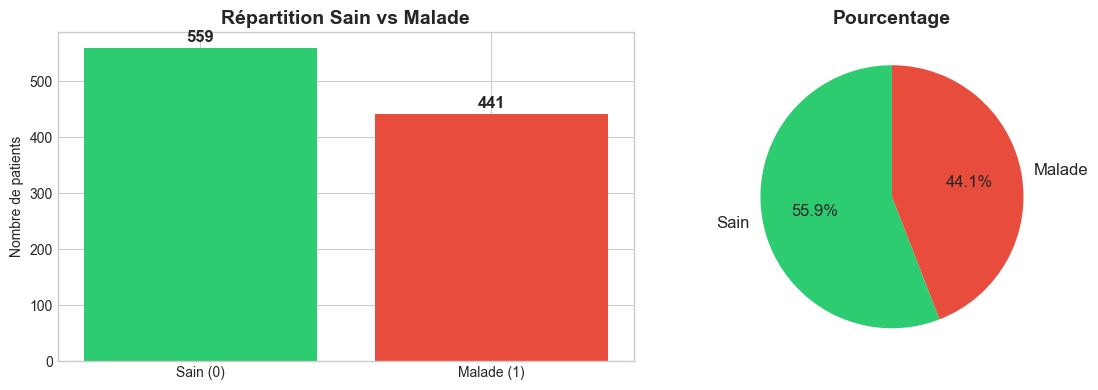

Sains   : 559 patients (55.9%)
Malades : 441 patients (44.1%)


In [30]:
# ---- 3.1 : Distribution de la cible (malade ou pas ?) ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Diagramme en barres
comptage = df['maladie_cardiaque'].value_counts()
axes[0].bar(['Sain (0)', 'Malade (1)'], comptage.values, color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Répartition Sain vs Malade', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Nombre de patients')
for i, v in enumerate(comptage.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold', fontsize=12)

# Diagramme circulaire
axes[1].pie(comptage.values, labels=['Sain', 'Malade'], colors=['#2ecc71', '#e74c3c'],
            autopct='%1.1f%%', startangle=90, textprops={'fontsize': 12})
axes[1].set_title('Pourcentage', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Sains   : {comptage[0]} patients ({comptage[0]/len(df)*100:.1f}%)")
print(f"Malades : {comptage[1]} patients ({comptage[1]/len(df)*100:.1f}%)")

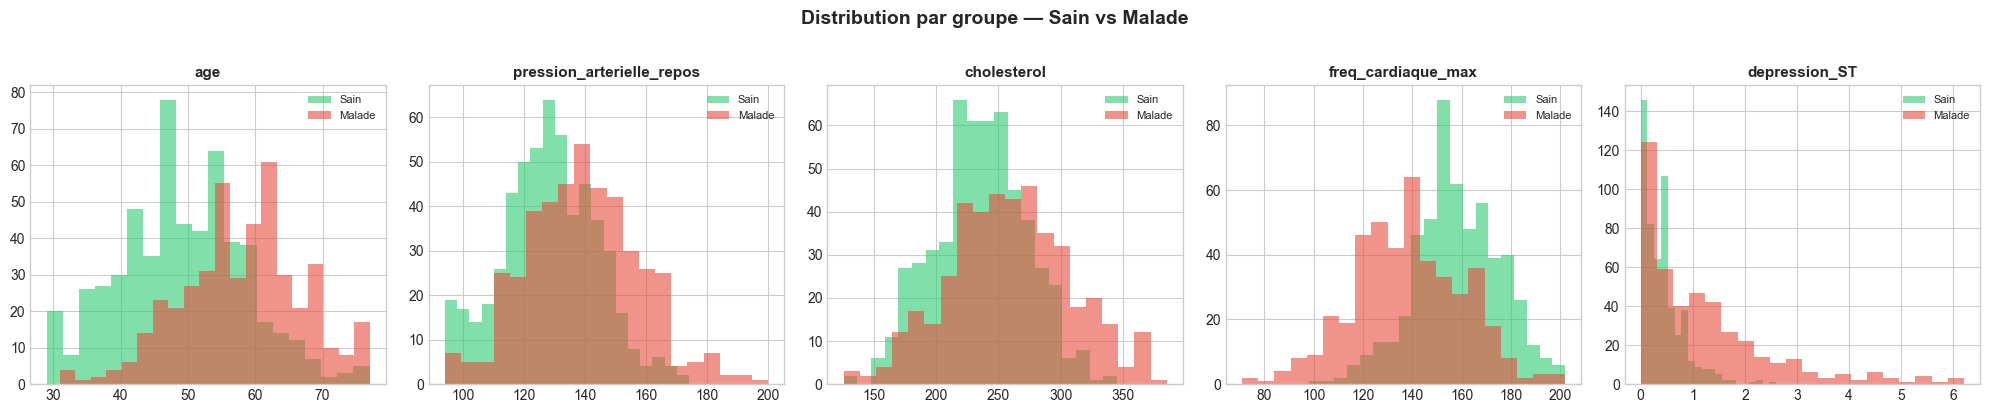

In [31]:
# ---- 3.3 : Comparer les distributions Sain vs Malade ----
# On compare quelques features clés entre les 2 groupes

features_a_comparer = ['age', 'pression_arterielle_repos', 'cholesterol',
                       'freq_cardiaque_max', 'depression_ST']

fig, axes = plt.subplots(1, len(features_a_comparer), figsize=(20, 4))

for i, col in enumerate(features_a_comparer):
    # Séparer les données en 2 groupes
    sains = df[df['maladie_cardiaque'] == 0][col].dropna()
    malades = df[df['maladie_cardiaque'] == 1][col].dropna()

    axes[i].hist(sains, bins=20, alpha=0.6, color='#2ecc71', label='Sain')
    axes[i].hist(malades, bins=20, alpha=0.6, color='#e74c3c', label='Malade')
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].legend(fontsize=8)

plt.suptitle('Distribution par groupe — Sain vs Malade', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 4. Prétraitement des données

Étapes :
1. **Valeurs manquantes** → remplir avec la médiane
2. **Encodage** → les colonnes catégorielles sont déjà sous forme numérique (0, 1, 2...)
3. **Normalisation** → StandardScaler sur toutes les features

In [32]:
# ---- 4.1 : Voir les valeurs manquantes ----
valeurs_manquantes = df.isnull().sum()
print("Valeurs manquantes par colonne :")
print("=" * 40)
print(valeurs_manquantes[valeurs_manquantes > 0])
print(f"\nTotal : {valeurs_manquantes.sum()} valeurs manquantes")

Valeurs manquantes par colonne :
pression_arterielle_repos    17
cholesterol                  33
ecg_repos                    15
freq_cardiaque_max           17
depression_ST                16
nb_vaisseaux_colores         42
thalassemie                  41
dtype: int64

Total : 181 valeurs manquantes


In [33]:
# ---- 4.2 : Remplir les valeurs manquantes avec la médiane ----
# La médiane est moins sensible aux valeurs extrêmes que la moyenne

colonnes_avec_nan = df.columns[df.isnull().any()].tolist()

for col in colonnes_avec_nan:
    mediane = df[col].median()
    df[col] = df[col].fillna(mediane)
    print(f"  {col} → rempli avec médiane = {mediane}")

print(f"\nValeurs manquantes restantes : {df.isnull().sum().sum()}")

  pression_arterielle_repos → rempli avec médiane = 132.0
  cholesterol → rempli avec médiane = 245.0
  ecg_repos → rempli avec médiane = 1.0
  freq_cardiaque_max → rempli avec médiane = 151.0
  depression_ST → rempli avec médiane = 0.4
  nb_vaisseaux_colores → rempli avec médiane = 1.0
  thalassemie → rempli avec médiane = 1.0

Valeurs manquantes restantes : 0


In [34]:
# ---- 4.3 : Séparer features (X) et cible (y) ----
# X = tout sauf la colonne "maladie_cardiaque"
# y = la colonne "maladie_cardiaque" (0 ou 1)

X = df.drop('maladie_cardiaque', axis=1).values
y = df['maladie_cardiaque'].values

print(f"X (features) : {X.shape} → {X.shape[0]} patients, {X.shape[1]} features")
print(f"y (cible)    : {y.shape} → valeurs uniques : {np.unique(y)}")
print(f"\nListe des features :")
for i, col in enumerate(df.columns[:-1], 1):
    print(f"  {i:2d}. {col}")

X (features) : (1000, 13) → 1000 patients, 13 features
y (cible)    : (1000,) → valeurs uniques : [0 1]

Liste des features :
   1. age
   2. sexe
   3. type_douleur_thoracique
   4. pression_arterielle_repos
   5. cholesterol
   6. glycemie_jeun
   7. ecg_repos
   8. freq_cardiaque_max
   9. angine_exercice
  10. depression_ST
  11. pente_ST
  12. nb_vaisseaux_colores
  13. thalassemie


## 5. Split Train/Test + Préparation PyTorch

In [35]:
# ---- Étape 1 : Séparer en Train (80%) et Test (20%) ----
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Train : {X_train.shape[0]} patients")
print(f"Test  : {X_test.shape[0]} patients")

# ---- Étape 2 : Normaliser les features ----
# StandardScaler → chaque colonne aura moyenne=0 et écart-type=1
# On fit sur le train, on transform le test (éviter le data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nAprès normalisation :")
print(f"  X_train → moyenne = {X_train_scaled.mean():.4f}, std = {X_train_scaled.std():.4f}")

Train : 800 patients
Test  : 200 patients

Après normalisation :
  X_train → moyenne = 0.0000, std = 1.0000


In [36]:
# ---- Étape 3 : Convertir en Tenseurs PyTorch ----
X_train_tensor = torch.FloatTensor(X_train_scaled).to(device)
y_train_tensor = torch.FloatTensor(y_train).reshape(-1, 1).to(device)
X_test_tensor  = torch.FloatTensor(X_test_scaled).to(device)
y_test_tensor  = torch.FloatTensor(y_test).reshape(-1, 1).to(device)

# ---- Étape 4 : Créer les DataLoaders ----
# On charge les données par petits groupes (batchs) de 32
BATCH_SIZE = 32

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset  = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Batch size          : {BATCH_SIZE}")
print(f"Batchs train        : {len(train_loader)}")
print(f"Batchs test         : {len(test_loader)}")
print(f"Nombre de features  : {X_train_tensor.shape[1]}")

Batch size          : 32
Batchs train        : 25
Batchs test         : 7
Nombre de features  : 13


## 6. Définition du MLP Classificateur

Architecture :
- **Entrée** → 13 features
- **Couche 1** : 64 neurones → ReLU → Dropout(0.3)
- **Couche 2** : 32 neurones → ReLU → Dropout(0.2)
- **Couche 3** : 16 neurones → ReLU
- **Sortie** : 1 neurone → **Sigmoid** (probabilité entre 0 et 1)

In [37]:
# ---- Définir le réseau de neurones ----
# MLP = Multi-Layer Perceptron (plusieurs couches de neurones empilées)
#
# Pour une classification binaire :
#   - Dernière couche → Sigmoid → donne une probabilité entre 0 et 1
#   - Si probabilité > 0.5 → on prédit "malade" (1)
#   - Si probabilité < 0.5 → on prédit "sain" (0)

class MLPClassifier(nn.Module):
    def __init__(self, nb_features):
        super(MLPClassifier, self).__init__()

        self.reseau = nn.Sequential(
            # Couche cachée 1 : 13 → 64 neurones
            nn.Linear(nb_features, 64),
            nn.ReLU(),         # activation (garde les valeurs positives)
            nn.Dropout(0.3),   # éteint 30% des neurones (évite le surapprentissage)

            # Couche cachée 2 : 64 → 32 neurones
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Couche cachée 3 : 32 → 16 neurones
            nn.Linear(32, 16),
            nn.ReLU(),

            # Couche de sortie : 16 → 1 neurone
            nn.Linear(16, 1),
            nn.Sigmoid()       # donne une probabilité entre 0 et 1
        )

    def forward(self, x):
        return self.reseau(x)


# Créer le modèle
nb_features = X_train_tensor.shape[1]   # 13
model = MLPClassifier(nb_features).to(device)

# Afficher l'architecture
print(model)
nb_params = sum(p.numel() for p in model.parameters())
print(f"\nNombre de paramètres : {nb_params:,}")

MLPClassifier(
  (reseau): Sequential(
    (0): Linear(in_features=13, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Linear(in_features=16, out_features=1, bias=True)
    (9): Sigmoid()
  )
)

Nombre de paramètres : 3,521


## 7. Configuration : BCELoss + Adam

In [38]:
# ---- Configurer l'entraînement ----

# 1) Fonction de perte : BCELoss (Binary Cross Entropy)
#    → Mesure l'erreur pour une classification binaire (0 ou 1)
criterion = nn.BCELoss()

# 2) Optimiseur : Adam
#    → Ajuste les poids du réseau pour réduire l'erreur
LEARNING_RATE = 0.001
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

print("Loss      : BCELoss (Binary Cross Entropy)")
print(f"Optimiseur : Adam (lr={LEARNING_RATE})")

Loss      : BCELoss (Binary Cross Entropy)
Optimiseur : Adam (lr=0.001)


## 8. Boucle d'Entraînement

On entraîne le modèle pendant plusieurs époques :
- **Forward pass** : le modèle fait une prédiction
- **Calcul de la loss** : on mesure l'erreur
- **Backward pass** : on calcule les gradients
- **Mise à jour** : l'optimiseur ajuste les poids

On utilise aussi l'**early stopping** : si la loss de test ne s'améliore plus après `patience` époques, on arrête.

In [39]:
# ---- Boucle d'entraînement ----

NB_EPOCHS = 200
PATIENCE = 20

# Listes pour sauvegarder l'historique
historique_loss_train = []
historique_loss_test = []

# Variables pour l'early stopping
meilleure_loss = float('inf')
compteur_patience = 0

for epoch in range(NB_EPOCHS):

    # ===== PHASE TRAIN =====
    model.train()
    total_loss_train = 0

    for X_batch, y_batch in train_loader:
        # 1) Prédiction
        predictions = model(X_batch)

        # 2) Calcul de la loss
        loss = criterion(predictions, y_batch)

        # 3) Remettre les gradients à zéro
        optimizer.zero_grad()

        # 4) Backward (calcul des gradients)
        loss.backward()

        # 5) Mise à jour des poids
        optimizer.step()

        total_loss_train += loss.item()

    # Loss moyenne sur tous les batchs
    loss_train_moyenne = total_loss_train / len(train_loader)
    historique_loss_train.append(loss_train_moyenne)

    # ===== PHASE TEST =====
    model.eval()
    total_loss_test = 0

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            total_loss_test += loss.item()

    loss_test_moyenne = total_loss_test / len(test_loader)
    historique_loss_test.append(loss_test_moyenne)

    # Afficher toutes les 20 époques
    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch+1:3d}/{NB_EPOCHS} | "
              f"Loss Train: {loss_train_moyenne:.4f} | "
              f"Loss Test: {loss_test_moyenne:.4f}")

    # ===== EARLY STOPPING =====
    if loss_test_moyenne < meilleure_loss:
        meilleure_loss = loss_test_moyenne
        compteur_patience = 0
        # Sauvegarder le meilleur modèle
        torch.save(model.state_dict(), "mlp_heart_disease_best.pth")
    else:
        compteur_patience += 1
        if compteur_patience >= PATIENCE:
            print(f"\n⛔ Early stopping à l'époque {epoch+1}")
            break

print(f"\n✅ Entraînement terminé !")
print(f"Meilleure loss test : {meilleure_loss:.4f}")

Époque  20/200 | Loss Train: 0.1582 | Loss Test: 0.1817

⛔ Early stopping à l'époque 32

✅ Entraînement terminé !
Meilleure loss test : 0.1793


## 9. Courbes de Loss (Train vs Test)

On visualise l'évolution de la loss pendant l'entraînement pour vérifier :
- Que le modèle **apprend** (loss qui diminue)
- Qu'il n'y a pas de **surapprentissage** (overfitting = loss test qui remonte)

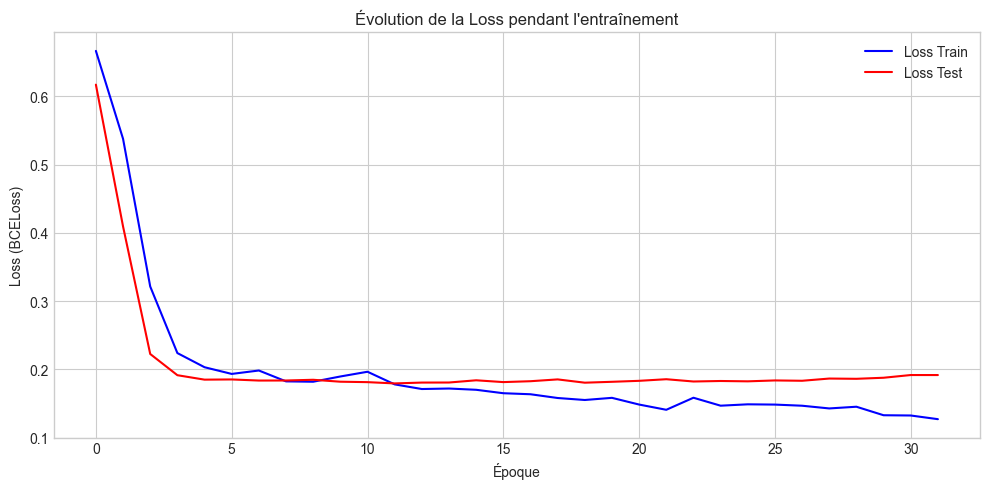

In [40]:
# ---- Tracer les courbes de loss ----

plt.figure(figsize=(10, 5))
plt.plot(historique_loss_train, label="Loss Train", color="blue")
plt.plot(historique_loss_test, label="Loss Test", color="red")
plt.xlabel("Époque")
plt.ylabel("Loss (BCELoss)")
plt.title("Évolution de la Loss pendant l'entraînement")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 10. Évaluation du Modèle

On charge le **meilleur modèle** (sauvegardé avec early stopping) et on calcule :
- **Accuracy** : % de bonnes prédictions
- **Precision** : parmi les prédits "malade", combien le sont vraiment ?
- **Recall** : parmi les vrais malades, combien sont détectés ?
- **F1-Score** : moyenne harmonique de Precision et Recall
- **Matrice de confusion** : tableau des erreurs

In [41]:
# ---- Charger le meilleur modèle et évaluer ----

# Charger les poids du meilleur modèle
model.load_state_dict(torch.load("mlp_heart_disease_best.pth", weights_only=True))
model.eval()

# Faire les prédictions sur le jeu de test
with torch.no_grad():
    probabilites = model(X_test_tensor)
    # Si proba > 0.5 → malade (1), sinon → sain (0)
    predictions_classes = (probabilites >= 0.5).float()

# Convertir en numpy pour sklearn
y_vrai = y_test_tensor.cpu().numpy()
y_predit = predictions_classes.cpu().numpy()

# ---- Calculer les métriques ----
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

accuracy = accuracy_score(y_vrai, y_predit)
precision = precision_score(y_vrai, y_predit)
recall = recall_score(y_vrai, y_predit)
f1 = f1_score(y_vrai, y_predit)

print("=" * 50)
print("       RÉSULTATS DU MODÈLE MLP")
print("=" * 50)
print(f"  Accuracy  : {accuracy:.4f}  ({accuracy*100:.1f}%)")
print(f"  Precision : {precision:.4f}")
print(f"  Recall    : {recall:.4f}")
print(f"  F1-Score  : {f1:.4f}")
print("=" * 50)
print()
print("Rapport de classification détaillé :")
print(classification_report(y_vrai, y_predit, target_names=["Sain", "Malade"]))

       RÉSULTATS DU MODÈLE MLP
  Accuracy  : 0.9300  (93.0%)
  Precision : 0.9375
  Recall    : 0.8929
  F1-Score  : 0.9146

Rapport de classification détaillé :
              precision    recall  f1-score   support

        Sain       0.93      0.96      0.94       116
      Malade       0.94      0.89      0.91        84

    accuracy                           0.93       200
   macro avg       0.93      0.92      0.93       200
weighted avg       0.93      0.93      0.93       200



## 12. Sauvegarde du Modèle Final

In [42]:
# ---- Sauvegarder le modèle final ----

chemin_sauvegarde = "mlp_heart_disease.pth"
torch.save(model.state_dict(), chemin_sauvegarde)
print(f"✅ Modèle sauvegardé dans : {chemin_sauvegarde}")

✅ Modèle sauvegardé dans : mlp_heart_disease.pth


## 13. Conclusion

### Résumé du projet :

| Étape | Description |
|-------|-------------|
| **Données** | 1000 patients, 13 features médicales, cible binaire |
| **Prétraitement** | Imputation médiane + StandardScaler |
| **Modèle** | MLP PyTorch (3 couches : 64→32→16) avec Dropout |
| **Loss** | BCELoss (Binary Cross Entropy) |
| **Optimiseur** | Adam (lr=0.001) |
| **Régularisation** | Dropout + Early Stopping |

### Points clés :
- Le **MLP** est un réseau de neurones simple mais puissant pour la classification binaire
- Le **Dropout** aide à éviter le surapprentissage (overfitting)
- L'**Early Stopping** arrête l'entraînement au bon moment
- La **courbe ROC** et l'**AUC** sont les meilleures métriques pour évaluer un classifieur médical
- Le **Recall** est crucial en médecine : il vaut mieux détecter un malade par erreur que de le rater !